For checking pipeline against selected low-pass ARTEMIS data.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
from lunarmag import run_passes

REPO = Path.cwd().resolve().parent
RAW, DERIVED = REPO / 'data' / 'raw', REPO / 'data' / 'derived'
DERIVED.mkdir(parents=True, exist_ok=True)

/Users/yulun/artemis-lunar-plasma/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load pass list from raw data file:

In [2]:
passes = pd.read_csv(RAW / 'thb_2012_2025_all_passes.csv')
passes['pass_id'] = passes['year'].astype(str) + '-' + passes['pass_number'].astype(str).str.zfill(2)
passes['t_peri'] = pd.to_datetime(passes['lowest_minute_utc']).dt.strftime('%Y-%m-%d/%H:%M:%S')

print(len(passes), 'passes; IDs unique:', passes['pass_id'].is_unique)
passes[['pass_id', 't_peri', 'lowest_altitude_km', 'latitude_deg', 'longitude_deg', 'sza_deg', 'phi_gse_deg']].head()

142 passes; IDs unique: True


,pass_id,t_peri,lowest_altitude_km,latitude_deg,longitude_deg,sza_deg,phi_gse_deg
0,2012-01,2012-01-19/20:25:00,38.5,9.05,274.32,47.76,-44.51
1,2012-02,2012-01-20/23:34:00,79.3,8.81,261.57,48.74,-29.79
2,2012-03,2012-02-02/13:30:00,67.0,10.09,89.02,30.14,116.05
3,2012-04,2012-02-15/03:18:00,49.2,10.49,280.95,16.26,-84.46
4,2012-05,2012-02-16/06:28:00,46.7,10.70,263.66,13.63,-69.89


List for overview of data:

In [3]:
print(passes.groupby('year').size().to_dict())
passes[['lowest_altitude_km', 'sza_deg', 'latitude_deg', 'duration_min']].describe().round(1)

{2012: 18, 2013: 15, 2014: 11, 2015: 8, 2016: 11, 2017: 9, 2018: 7, 2019: 9, 2020: 10, 2021: 6, 2022: 13, 2023: 9, 2024: 6, 2025: 10}


,lowest_altitude_km,sza_deg,latitude_deg,duration_min
count,142.0,142.0,142.0,142.0
mean,77.6,59.1,0.5,4.8
std,18.6,26.8,7.5,2.5
min,14.8,8.5,-10.9,1.0
25%,69.2,38.0,-7.1,3.0
50%,82.0,65.8,1.3,5.0
75%,90.7,84.4,7.9,6.0
max,99.7,89.9,10.9,12.0


Trial run on three passes first:

In [4]:
trial_ids = ['2013-12', '2013-13', '2013-14']
trial = passes[passes['pass_id'].isin(trial_ids)]

results, failures = run_passes(trial['t_peri'].tolist(), ids=trial['pass_id'])
failures

23-Nov-26 17:28:05: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131202_v01.cdf
23-Nov-26 17:28:05: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131202_v01.cdf
23-Nov-26 17:28:06: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:28:06: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:28:06: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:28:06: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:28:06: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:28:07: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131202.cdf
23-Nov-26 17:28:07: Creating spin model for probe b correction level 0
23-Nov-26 17:28:07: spin_correction variable not available, defaulting to 0.0
23-Nov-26 17:28:07: FGM correction variables not available
23-Nov-26 17:28:07: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 17:28:07: Creating spin model for probe b co

1/3 done, 0 failed

23-Nov-26 17:28:18: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
23-Nov-26 17:28:19: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
23-Nov-26 17:28:19: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
23-Nov-26 17:28:20: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
23-Nov-26 17:28:21: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:28:21: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:28:22: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:28:22: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:28:22: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:28:22: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131203.cdf
23-Nov-26 17:28:23: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
23-Nov-26 17:28:23: Creating spin model for probe b correction level 

2/3 done, 0 failed

23-Nov-26 17:28:41: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 17:28:41: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 17:28:42: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:28:42: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:28:42: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:28:42: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:28:42: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:28:42: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 17:28:42: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 17:28:42: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed

""


Success! Check against data columns:

In [5]:
print(results.shape, passes.shape)
failures

(3, 32) (142, 21)


""


In [6]:
table = results.merge(passes, on='pass_id', suffixes=('', '_margot'))
table[['pass_id', 'min_alt_km', 'lowest_altitude_km', 'tail_angle_deg', 'phi_gse_deg', 'regime_geo', 'bg_ok', 'bg_sigma', 'post_status', 'n_used', 'peak_dB', 'peak_dBi']]

,pass_id,min_alt_km,lowest_altitude_km,tail_angle_deg,phi_gse_deg,regime_geo,bg_ok,bg_sigma,post_status,n_used,peak_dB,peak_dBi
0,2013-12,33.151552,33.5,175.613516,-0.66,solar_wind,False,0.911649,ok,248,2.988227,2.701883
1,2013-13,14.786443,14.8,161.731000,13.85,solar_wind,True,0.399926,disturbed,248,6.515042,5.717913
2,2013-14,86.387652,86.7,147.219551,28.47,solar_wind,True,0.149600,disturbed,276,3.356956,3.281770


In [7]:
stamp = pd.Timestamp.today().strftime('%Y-%m-%d')
results.to_csv(DERIVED / f'trial_results_{stamp}.csv', index=False)
failures.to_csv(DERIVED / f'trial_failures_{stamp}.csv', index=False)

All three passes asssociated with disturbed post_status and two had failed backgrounds. Check how tests failed:

In [8]:
table[['pass_id', 'bg_sigma', 'bg_r', 'bg_shift', 'post_window', 'post_sigma', 'post_shift', 'shadow_s']]

,pass_id,bg_sigma,bg_r,bg_shift,post_window,post_sigma,post_shift,shadow_s
0,2013-12,0.911649,0.754562,120.0,"(1386026190.0, 1386026370.0)",0.474022,-38.0,780.0
1,2013-13,0.399926,0.940293,12.0,"(1386116100.0, 1386116280.0)",2.050849,16.0,780.0
2,2013-14,0.149600,0.735600,-23.0,"(1386206040.0, 1386206220.0)",0.897016,45.0,600.0


2013-12: fails on noise and delay (bg_sigma and ng_shift, 120 at edge); also shift is negative, i.e. THC downstream from THB.

2013-13: passes!

2013-14: fails since we set r_min = 0.8 in background.py. Changed to 0.5 instead.

In [9]:
table = results.merge(passes, on='pass_id', suffixes=('', 'list'))
t0 = table['t_peri']
table['bg_start_s'] = [w[0] - tp for w, tp in zip(table['bg_window'], t0)]
table[['pass_id', 'bg_ok', 'bg_sigma', 'bg_r', 'bg_shift', 'bg_start_s','post_status', 'post_sigma', 'n_used', 'peak_dB', 'peak_dBi']]

,pass_id,bg_ok,bg_sigma,bg_r,bg_shift,bg_start_s,post_status,post_sigma,n_used,peak_dB,peak_dBi
0,2013-12,False,0.911649,0.754562,120.0,-840.0,ok,0.474022,248,2.988227,2.701883
1,2013-13,True,0.399926,0.940293,12.0,-480.0,disturbed,2.050849,248,6.515042,5.717913
2,2013-14,True,0.149600,0.735600,-23.0,-1170.0,disturbed,0.897016,276,3.356956,3.281770


Fitting window is problematic after applying criteria that THB must be above 0.5 lunar radii (870 km, c.f. Liuzzo et al. for ambient plasma), since THB spends most time below this cut. Check different windows to see which ones yield stable fits:

In [10]:
rows = []
for h in [0, 200, 500, 870]:
    res, fails = run_passes(trial['t_peri'].tolist(), ids=trial['pass_id'], bg_alt_min=h)
    res['bg_alt_min'] = h
    res['bg_start_s'] = [w[0] - tp for w, tp in zip(res['bg_window'], res['t_peri'])]
    rows.append(res)
    print(f'  bg_alt_min = {h}: {len(fails)} failed')

sweep = pd.concat(rows, ignore_index=True)
sweep.pivot_table(index='pass_id', columns='bg_alt_min', values=['bg_sigma', 'bg_shift', 'bg_start_s', 'bg_ok'], aggfunc='first')

23-Nov-26 17:28:53: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131202_v01.cdf
23-Nov-26 17:28:53: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131202_v01.cdf
23-Nov-26 17:28:54: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:28:54: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:28:54: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:28:54: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:28:54: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:28:55: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131202.cdf
23-Nov-26 17:28:55: Creating spin model for probe b correction level 0
23-Nov-26 17:28:55: spin_correction variable not available, defaulting to 0.0
23-Nov-26 17:28:55: FGM correction variables not available
23-Nov-26 17:28:55: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 17:28:55: Creating spin model for probe b co

1/3 done, 0 failed

23-Nov-26 17:29:07: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
23-Nov-26 17:29:07: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
23-Nov-26 17:29:08: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
23-Nov-26 17:29:08: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
23-Nov-26 17:29:10: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:29:10: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:29:10: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:29:10: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:29:10: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:29:11: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131203.cdf
23-Nov-26 17:29:11: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
23-Nov-26 17:29:11: Creating spin model for probe b correction level 

2/3 done, 0 failed

23-Nov-26 17:29:29: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 17:29:29: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 17:29:30: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:29:30: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:29:30: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:29:30: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:29:30: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:29:30: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 17:29:30: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 17:29:30: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed  bg_alt_min = 0: 0 failed


... (15 outputs left out)

2/3 done, 0 failed

23-Nov-26 17:31:47: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 17:31:47: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 17:31:48: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:31:48: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:31:48: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:31:48: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:31:48: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:31:48: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 17:31:48: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 17:31:48: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed  bg_alt_min = 870: 0 failed


bg_ok                      bg_shift                       \
bg_alt_min    0      200    500    870      0      200    500    870   
pass_id                                                                
2013-12     False  False  False  False    120.0  120.0  113.0   22.0   
2013-13      True  False   True  False     12.0   16.0    0.0  -86.0   
2013-14      True   True   True  False    -23.0  -23.0  -23.0  120.0   

            bg_sigma                               bg_start_s                  \
bg_alt_min       0         200       500       870        0       200     500   
pass_id                                                                         
2013-12     0.911649  0.911649  0.605633  0.596116     -840.0  -840.0 -1140.0   
2013-13     0.399926  0.664617  0.465003  0.993630     -480.0  -810.0 -1140.0   
2013-14     0.149600  0.149600  0.149600  0.313044    -1170.0 -1170.0 -1170.0   

                    
bg_alt_min     870  
pass_id             
2013-12    -1650.0  
2013-13    -1800.0  
2013-14    -1560.0

Check for 2013-12 if true delay lies outside of 120s interval:

In [11]:
res, fails = run_passes(trial['t_peri'].tolist(), ids=trial['pass_id'], max_lag=300)
res[['pass_id', 'bg_ok', 'bg_sigma', 'bg_r', 'bg_shift']]

23-Nov-26 17:40:54: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131202_v01.cdf
23-Nov-26 17:40:55: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131202_v01.cdf
23-Nov-26 17:40:56: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:40:56: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:40:56: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:40:56: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:40:56: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:40:56: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131202.cdf
23-Nov-26 17:40:57: Creating spin model for probe b correction level 0
23-Nov-26 17:40:57: spin_correction variable not available, defaulting to 0.0
23-Nov-26 17:40:57: FGM correction variables not available
23-Nov-26 17:40:57: Skipping FGM corrections, do_fgm_corr False, correction_level = 0
23-Nov-26 17:40:57: Creating spin model for probe b co

1/3 done, 0 failed

23-Nov-26 17:41:10: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131203_v01.cdf
23-Nov-26 17:41:10: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf
23-Nov-26 17:41:11: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131203_v01.cdf
23-Nov-26 17:41:11: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131204_v01.cdf
23-Nov-26 17:41:13: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:41:13: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:41:13: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:41:13: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:41:13: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:41:14: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131203.cdf
23-Nov-26 17:41:14: File is current: themis_data/thb/l1/state/2013/thb_l1_state_20131204.cdf
23-Nov-26 17:41:14: Creating spin model for probe b correction level 

2/3 done, 0 failed

23-Nov-26 17:41:34: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131205_v01.cdf
23-Nov-26 17:41:34: File is current: themis_data/thc/l2/fgm/2013/thc_l2_fgm_20131205_v01.cdf
23-Nov-26 17:41:35: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:41:35: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:41:35: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:41:35: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:41:35: time_clip: thc_fgh_ssl has no data in requested range
23-Nov-26 17:41:35: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 17:41:35: Eclipse 1 of 3: start: 2013-12-03 00:00:01.401909  end: 2013-12-03 00:23:43.143876 status: in shadow, partially corrected (field waveforms corrected; particle data and EFI or FGM spin fits will have uncorrected spin phase offsets)
23-Nov-26 17:41:35: Eclipse 2 of 3: start: 2013-12-04 00:20:12.474808  end: 2013-12-04 01:21:21.007147 status: in shadow, 

3/3 done, 0 failed

,pass_id,bg_ok,bg_sigma,bg_r,bg_shift
0,2013-12,False,0.877199,0.802704,208.0
1,2013-13,True,0.399926,0.940293,12.0
2,2013-14,True,0.149600,0.735600,-23.0


Sigma still clearly not ok (>0.5), despite extended search times. Whatever. run a batch for bants:

In [12]:
stamp = pd.Timestamp.today().strftime('%Y-%m-%d')
out = DERIVED / f'batch_{stamp}'
out.mkdir(exist_ok=True)

#run one year at a time, and save each year as it finishes
for year, grp in passes.groupby('year'):
    f_res = out / f'results_{year}.csv'
    if f_res.exists():
        print(year, 'already done'); continue
    res, fails = run_passes(grp['t_peri'].tolist(), ids=grp['pass_id'])
    res.to_csv(f_res, index=False)
    fails.to_csv(out / f'failures_{year}.csv', index=False)
    print(f'  {year}: {len(res)} ok, {len(fails)} failed')

23-Nov-26 17:49:33: Downloading https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2012/thb_l2_fgm_20120119_v01.cdf to themis_data/thb/l2/fgm/2012/thb_l2_fgm_20120119_v01.cdf
23-Nov-26 17:49:34: Download of themis_data/thb/l2/fgm/2012/thb_l2_fgm_20120119_v01.cdf complete, 6.379 MB in 1.7 sec (3.843 MB/sec) (transfer_normal)
23-Nov-26 17:49:35: Downloading https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2012/thc_l2_fgm_20120119_v01.cdf to themis_data/thc/l2/fgm/2012/thc_l2_fgm_20120119_v01.cdf
23-Nov-26 17:49:36: Download of themis_data/thc/l2/fgm/2012/thc_l2_fgm_20120119_v01.cdf complete, 7.702 MB in 1.7 sec (4.643 MB/sec) (transfer_normal)
23-Nov-26 17:49:36: time_clip: thc_fgl_btotal has no data in requested range
23-Nov-26 17:49:36: time_clip: thc_fgl_gse has no data in requested range
23-Nov-26 17:49:36: time_clip: thc_fgl_gsm has no data in requested range
23-Nov-26 17:49:36: time_clip: thc_fgl_dsl has no data in requested range
23-Nov-26 17:49:36: time_clip: thc_fgl_ss

1/18 done, 0 failed

23-Nov-26 17:49:50: Downloading https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2012/thb_l2_fgm_20120120_v01.cdf to themis_data/thb/l2/fgm/2012/thb_l2_fgm_20120120_v01.cdf
23-Nov-26 17:49:51: Download of themis_data/thb/l2/fgm/2012/thb_l2_fgm_20120120_v01.cdf complete, 8.978 MB in 1.7 sec (5.312 MB/sec) (transfer_normal)
23-Nov-26 17:49:52: Downloading https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2012/thc_l2_fgm_20120120_v01.cdf to themis_data/thc/l2/fgm/2012/thc_l2_fgm_20120120_v01.cdf
23-Nov-26 17:49:54: Download of themis_data/thc/l2/fgm/2012/thc_l2_fgm_20120120_v01.cdf complete, 19.472 MB in 2.2 sec (8.934 MB/sec) (transfer_normal)
23-Nov-26 17:49:55: Eclipse correction status for probe ['b', 'c']:
23-Nov-26 17:49:55: Eclipse 1 of 2: start: 2012-01-19 18:16:22.786345  end: 2012-01-19 19:08:17.142554 status: in shadow, fully corrected
23-Nov-26 17:49:55: Eclipse 2 of 2: start: 2012-01-20 21:23:49.099152  end: 2012-01-20 22:13:13.537201 status: in shadow, fully corre

2/18 done, 0 failed

23-Nov-26 17:50:06: Downloading https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2012/thb_l2_fgm_20120202_v01.cdf to themis_data/thb/l2/fgm/2012/thb_l2_fgm_20120202_v01.cdf
23-Nov-26 17:50:08: Download of themis_data/thb/l2/fgm/2012/thb_l2_fgm_20120202_v01.cdf complete, 11.653 MB in 2.1 sec (5.559 MB/sec) (transfer_normal)
23-Nov-26 17:50:09: Downloading https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2012/thc_l2_fgm_20120202_v01.cdf to themis_data/thc/l2/fgm/2012/thc_l2_fgm_20120202_v01.cdf
23-Nov-26 17:50:10: Download of themis_data/thc/l2/fgm/2012/thc_l2_fgm_20120202_v01.cdf complete, 14.250 MB in 2.0 sec (7.261 MB/sec) (transfer_normal)
23-Nov-26 17:50:11: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 17:50:11: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 17:50:11: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 17:50:11: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 17:50:11: time_clip: thc_fgh_

3/18 done, 0 failed

... (274 outputs left out)

23-Nov-26 18:32:54: Downloading https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2025/thb_l2_fgm_20251220_v01.cdf to themis_data/thb/l2/fgm/2025/thb_l2_fgm_20251220_v01.cdf
23-Nov-26 18:32:55: Download of themis_data/thb/l2/fgm/2025/thb_l2_fgm_20251220_v01.cdf complete, 0.915 MB in 1.2 sec (0.776 MB/sec) (transfer_normal)
23-Nov-26 18:32:55: Downloading https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2025/thc_l2_fgm_20251220_v01.cdf to themis_data/thc/l2/fgm/2025/thc_l2_fgm_20251220_v01.cdf
23-Nov-26 18:32:57: Download of themis_data/thc/l2/fgm/2025/thc_l2_fgm_20251220_v01.cdf complete, 12.477 MB in 2.1 sec (5.973 MB/sec) (transfer_normal)
23-Nov-26 18:32:57: time_clip: thc_fgl_btotal has no data in requested range
23-Nov-26 18:32:57: time_clip: thc_fgl_gse has no data in requested range
23-Nov-26 18:32:57: time_clip: thc_fgl_gsm has no data in requested range
23-Nov-26 18:32:58: time_clip: thc_fgl_dsl has no data in requested range
23-Nov-26 18:32:58: time_clip: thc_fgl_s

9/10 done, 2 failed

23-Nov-26 18:33:07: Downloading https://themis.ssl.berkeley.edu/data/themis/thb/l2/fgm/2025/thb_l2_fgm_20251221_v01.cdf to themis_data/thb/l2/fgm/2025/thb_l2_fgm_20251221_v01.cdf
23-Nov-26 18:33:08: Download of themis_data/thb/l2/fgm/2025/thb_l2_fgm_20251221_v01.cdf complete, 0.933 MB in 1.2 sec (0.798 MB/sec) (transfer_normal)
23-Nov-26 18:33:08: Downloading https://themis.ssl.berkeley.edu/data/themis/thc/l2/fgm/2025/thc_l2_fgm_20251221_v01.cdf to themis_data/thc/l2/fgm/2025/thc_l2_fgm_20251221_v01.cdf
23-Nov-26 18:33:11: Download of themis_data/thc/l2/fgm/2025/thc_l2_fgm_20251221_v01.cdf complete, 30.373 MB in 2.7 sec (11.215 MB/sec) (transfer_normal)
23-Nov-26 18:33:11: time_clip: thc_fgh_btotal has no data in requested range
23-Nov-26 18:33:11: time_clip: thc_fgh_gse has no data in requested range
23-Nov-26 18:33:11: time_clip: thc_fgh_gsm has no data in requested range
23-Nov-26 18:33:12: time_clip: thc_fgh_dsl has no data in requested range
23-Nov-26 18:33:12: time_clip: thc_fgh_

10/10 done, 2 failed  2025: 8 ok, 2 failed


In [14]:
def read_all(pattern):
    """Read and combine the CSVs matching pattern, skipping empty ones."""
    files = [f for f in sorted(out.glob(pattern)) if f.stat().st_size > 1]
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else pd.DataFrame()

results = read_all('results_*.csv')
failures = read_all('failures_*.csv')
print(len(results), 'ran,', len(failures), 'failed')
failures['error'].value_counts() if len(failures) else 'no failures'

119 ran, 23 failed


error
RuntimeError: no quiet window with enough data before periapsis                 19
RuntimeError: thc: FGM data do not contain periapsis (stale or missing data)     4
Name: count, dtype: int64

In [15]:
print(len(results), 'ran;', results['bg_ok'].mean().round(2), 'with good background')
results['post_status'].value_counts()

119 ran; 0.44 with good background


post_status
disturbed    78
ok           28
none         13
Name: count, dtype: int64

Stats:

In [16]:
print(pd.crosstab(results['bg_ok'], results['post_status'], margins=True), '\n')

bad = results[~results['bg_ok']]
print('not ok:', len(bad))
print('  sigma > 0.5      :', (bad['bg_sigma'] > 0.5).sum())
print('  r < 0.5          :', (bad['bg_r'] < 0.5).sum())
print('  shift at the edge:', (bad['bg_shift'].abs() >= 120).sum())

post_status  disturbed  none  ok  All
bg_ok                                
False               49     4  14   67
True                29     9  14   52
All                 78    13  28  119 

not ok: 67
  sigma > 0.5      : 66
  r < 0.5          : 5
  shift at the edge: 2


Check distribution:

Text(0, 0.5, 'peak |ΔB| (nT)')

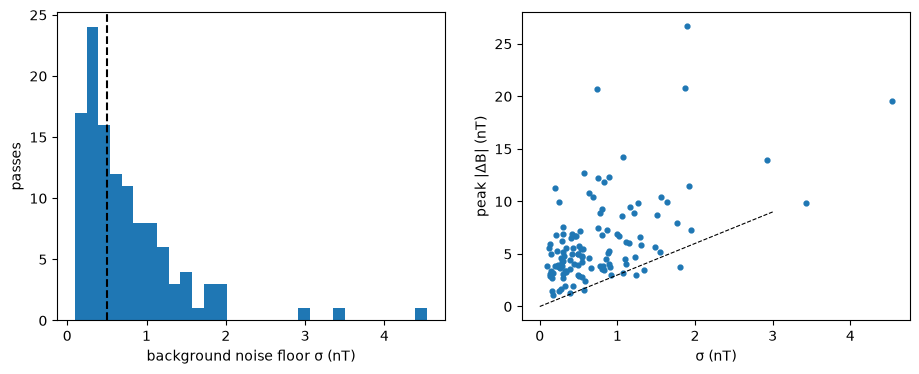

In [17]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(results['bg_sigma'], bins=30)
axs[0].axvline(0.5, color='k', ls='--')
axs[0].set_xlabel('background noise floor σ (nT)'); axs[0].set_ylabel('passes')

axs[1].scatter(results['bg_sigma'], results['peak_dB'], s=12)
axs[1].plot([0, 3], [0, 9], 'k--', lw=0.8)           # line peak = 3σ
axs[1].set_xlabel('σ (nT)'); axs[1].set_ylabel('peak |ΔB| (nT)')

In [18]:
fit_valid = (results['bg_r'] >= 0.5) & (results['bg_shift'].abs() < 120)
sig = results['peak_dB'] / results['bg_sigma']

for smax in [0.5, 1.0, 2.0]:
    ok = fit_valid & (results['bg_sigma'] <= smax)
    print(f'sigma <= {smax}: {ok.sum():3d} valid,  {(ok & (sig >= 3)).sum():3d} at >=3σ,  {(ok & (sig >= 5)).sum():3d} at >=5σ')

cand = results[fit_valid & (results['bg_sigma'] <= 2.0) & (sig >= 5)].assign(signif=sig)
cand.sort_values('peak_dBi', ascending=False)[
    ['pass_id', 'min_alt_km', 'sza_peri', 'tail_angle_deg', 'bg_sigma', 'peak_svm', 'peak_dB', 'peak_dBi', 'signif']].head(10)

sigma <= 0.5:  52 valid,   52 at >=3σ,   50 at >=5σ
sigma <= 1.0:  84 valid,   83 at >=3σ,   77 at >=5σ
sigma <= 2.0: 110 valid,  105 at >=3σ,   92 at >=5σ


,pass_id,min_alt_km,sza_peri,tail_angle_deg,bg_sigma,peak_svm,peak_dB,peak_dBi,signif
61,2018-05,68.795998,95.086692,165.455976,1.898114,0.955732,26.646231,26.810216,14.038269
94,2022-08,99.418845,10.486184,109.180572,0.742672,0.413258,20.658782,20.761797,27.816849
99,2022-13,87.468795,76.188326,158.017434,1.872174,0.580054,20.760654,20.663783,11.089063
56,2017-09,95.796049,60.194620,149.114265,1.073366,0.477826,14.224993,14.124112,13.252691
11,2012-14,84.062297,72.545646,150.174792,0.568961,0.576154,12.737474,12.850148,22.387264
113,2025-03,73.651010,87.588660,172.728380,0.755752,0.337191,12.182981,12.180845,16.120343
58,2018-02,96.109413,62.409087,162.262166,0.894973,0.564494,12.313375,12.148841,13.758377
20,2013-07,26.302239,78.360912,156.148737,0.639250,3.250112,10.819343,12.024916,16.925064
16,2013-03,99.373487,44.599604,147.281516,0.831538,0.782022,11.868737,11.709183,14.273232
115,2025-07,84.757241,55.245740,132.367851,1.925193,0.368427,11.510725,11.431040,5.978999
